In [ ]:

from google.colab import files
uploaded = files.upload()

Saving train.csv to train.csv


In [ ]:
import pandas as pd

In [ ]:
df = pd.read_csv("train.csv")

In [ ]:
print(df.shape)

(1460, 81)


In [ ]:
df.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460 non-null   int64  
 18  OverallC

In [ ]:
df.isnull().sum()

,0
Id,0
MSSubClass,0
MSZoning,0
LotFrontage,259
LotArea,0
...,...
MoSold,0
YrSold,0
SaleType,0
SaleCondition,0


In [ ]:
df.isnull().sum().sort_values(ascending=False)

,0
PoolQC,1453
MiscFeature,1406
Alley,1369
Fence,1179
MasVnrType,872
...,...
MoSold,0
YrSold,0
SaleType,0
SaleCondition,0


In [ ]:
(df.isnull().sum() / len(df)) * 100

,0
Id,0.000000
MSSubClass,0.000000
MSZoning,0.000000
LotFrontage,17.739726
LotArea,0.000000
...,...
MoSold,0.000000
YrSold,0.000000
SaleType,0.000000
SaleCondition,0.000000


In [ ]:
missing = pd.DataFrame({
    'Missing Values': df.isnull().sum(),
    'Missing Percentage': (df.isnull().sum() / len(df)) * 100
})

missing = missing[missing['Missing Values'] > 0]

missing.sort_values(by='Missing Percentage', ascending=False)

,Missing Values,Missing Percentage
PoolQC,1453,99.520548
MiscFeature,1406,96.301370
Alley,1369,93.767123
Fence,1179,80.753425
MasVnrType,872,59.726027
FireplaceQu,690,47.260274
LotFrontage,259,17.739726
GarageType,81,5.547945
GarageYrBlt,81,5.547945
GarageFinish,81,5.547945


In [ ]:
df.describe()

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.000000,1460.000000,1201.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1452.000000,1460.000000,...,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,730.500000,56.897260,70.049958,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.685262,443.639726,...,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,421.610009,42.300571,24.284752,9981.264932,1.382997,1.112799,30.202904,20.645407,181.066207,456.098091,...,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,1.000000,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,365.750000,20.000000,59.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,730.500000,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,...,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,1095.250000,70.000000,80.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,166.000000,712.250000,...,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,1460.000000,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,...,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000


In [ ]:
df.describe(include='object')

,MSZoning,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,...,GarageType,GarageFinish,GarageQual,GarageCond,PavedDrive,PoolQC,Fence,MiscFeature,SaleType,SaleCondition
count,1460,1460,91,1460,1460,1460,1460,1460,1460,1460,...,1379,1379,1379,1379,1460,7,281,54,1460,1460
unique,5,2,2,4,4,2,5,3,25,9,...,6,3,5,5,3,3,4,4,9,6
top,RL,Pave,Grvl,Reg,Lvl,AllPub,Inside,Gtl,NAmes,Norm,...,Attchd,Unf,TA,TA,Y,Gd,MnPrv,Shed,WD,Normal
freq,1151,1454,50,925,1311,1459,1052,1382,225,1260,...,870,605,1311,1326,1340,3,157,49,1267,1198


In [ ]:
df['SalePrice'].describe()

,SalePrice
count,1460.000000
mean,180921.195890
std,79442.502883
min,34900.000000
25%,129975.000000
50%,163000.000000
75%,214000.000000
max,755000.000000


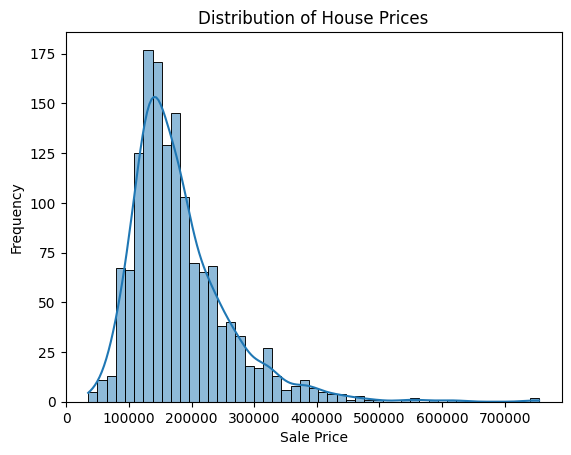

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.histplot(df['SalePrice'], kde=True)
plt.title('Distribution of House Prices')
plt.xlabel('Sale Price')
plt.ylabel('Frequency')
plt.show()

In [ ]:
print("Skewness:", df['SalePrice'].skew())

Skewness: 1.8828757597682129


In [ ]:
corr = df.corr(numeric_only=True)

In [ ]:
corr

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
Id,1.000000,0.011156,-0.010601,-0.033226,-0.028365,0.012609,-0.012713,-0.021998,-0.050298,-0.005024,...,-0.029643,-0.000477,0.002889,-0.046635,0.001330,0.057044,-0.006242,0.021172,0.000712,-0.021917
MSSubClass,0.011156,1.000000,-0.386347,-0.139781,0.032628,-0.059316,0.027850,0.040581,0.022936,-0.069836,...,-0.012579,-0.006100,-0.012037,-0.043825,-0.026030,0.008283,-0.007683,-0.013585,-0.021407,-0.084284
LotFrontage,-0.010601,-0.386347,1.000000,0.426095,0.251646,-0.059213,0.123349,0.088866,0.193458,0.233633,...,0.088521,0.151972,0.010700,0.070029,0.041383,0.206167,0.003368,0.011200,0.007450,0.351799
LotArea,-0.033226,-0.139781,0.426095,1.000000,0.105806,-0.005636,0.014228,0.013788,0.104160,0.214103,...,0.171698,0.084774,-0.018340,0.020423,0.043160,0.077672,0.038068,0.001205,-0.014261,0.263843
OverallQual,-0.028365,0.032628,0.251646,0.105806,1.000000,-0.091932,0.572323,0.550684,0.411876,0.239666,...,0.238923,0.308819,-0.113937,0.030371,0.064886,0.065166,-0.031406,0.070815,-0.027347,0.790982
OverallCond,0.012609,-0.059316,-0.059213,-0.005636,-0.091932,1.000000,-0.375983,0.073741,-0.128101,-0.046231,...,-0.003334,-0.032589,0.070356,0.025504,0.054811,-0.001985,0.068777,-0.003511,0.043950,-0.077856
YearBuilt,-0.012713,0.027850,0.123349,0.014228,0.572323,-0.375983,1.000000,0.592855,0.315707,0.249503,...,0.224880,0.188686,-0.387268,0.031355,-0.050364,0.004950,-0.034383,0.012398,-0.013618,0.522897
YearRemodAdd,-0.021998,0.040581,0.088866,0.013788,0.550684,0.073741,0.592855,1.000000,0.179618,0.128451,...,0.205726,0.226298,-0.193919,0.045286,-0.038740,0.005829,-0.010286,0.021490,0.035743,0.507101
MasVnrArea,-0.050298,0.022936,0.193458,0.104160,0.411876,-0.128101,0.315707,0.179618,1.000000,0.264736,...,0.159718,0.125703,-0.110204,0.018796,0.061466,0.011723,-0.029815,-0.005965,-0.008201,0.477493
BsmtFinSF1,-0.005024,-0.069836,0.233633,0.214103,0.239666,-0.046231,0.249503,0.128451,0.264736,1.000000,...,0.204306,0.111761,-0.102303,0.026451,0.062021,0.140491,0.003571,-0.015727,0.014359,0.386420


In [ ]:
corr['SalePrice'].sort_values(ascending=False)

,SalePrice
SalePrice,1.000000
OverallQual,0.790982
GrLivArea,0.708624
GarageCars,0.640409
GarageArea,0.623431
TotalBsmtSF,0.613581
1stFlrSF,0.605852
FullBath,0.560664
TotRmsAbvGrd,0.533723
YearBuilt,0.522897


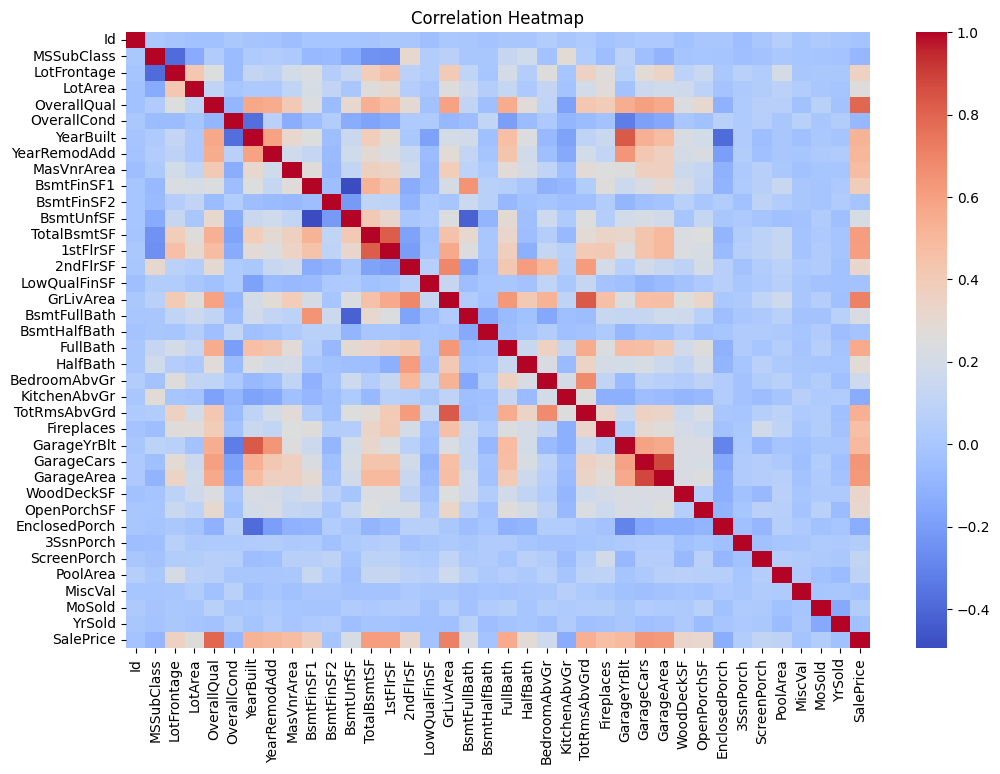

In [ ]:
plt.figure(figsize=(12, 8))

sns.heatmap(corr, cmap='coolwarm', annot=False)

plt.title('Correlation Heatmap')
plt.show()

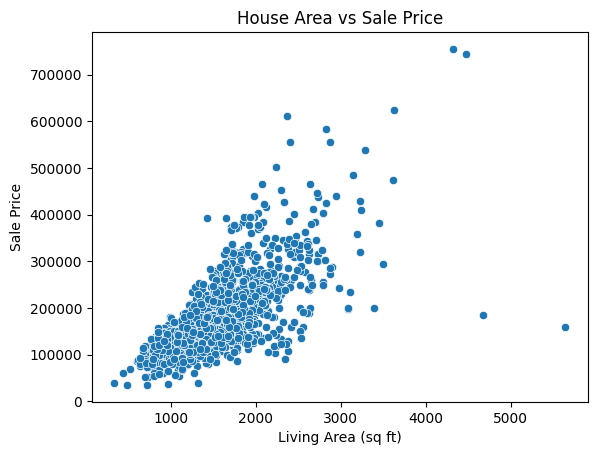

In [ ]:
sns.scatterplot(data=df, x='GrLivArea', y='SalePrice')

plt.title('House Area vs Sale Price')
plt.xlabel('Living Area (sq ft)')
plt.ylabel('Sale Price')
plt.show()

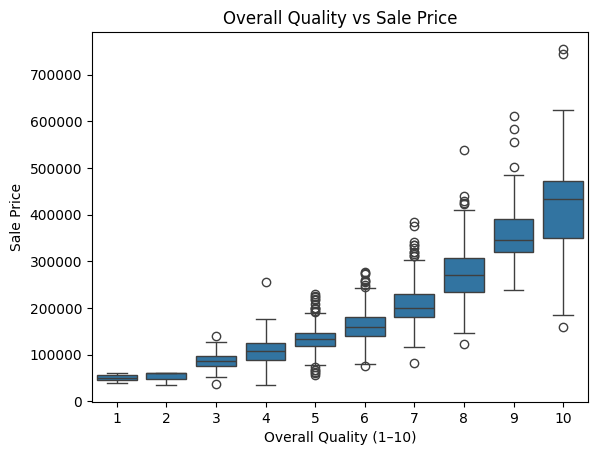

In [ ]:
sns.boxplot(data=df, x='OverallQual', y='SalePrice')

plt.title('Overall Quality vs Sale Price')
plt.xlabel('Overall Quality (1–10)')
plt.ylabel('Sale Price')
plt.show()

In [ ]:
df['HouseStyle'].value_counts()

,count
HouseStyle,
1Story,726
2Story,445
1.5Fin,154
SLvl,65
SFoyer,37
1.5Unf,14
2.5Unf,11
2.5Fin,8


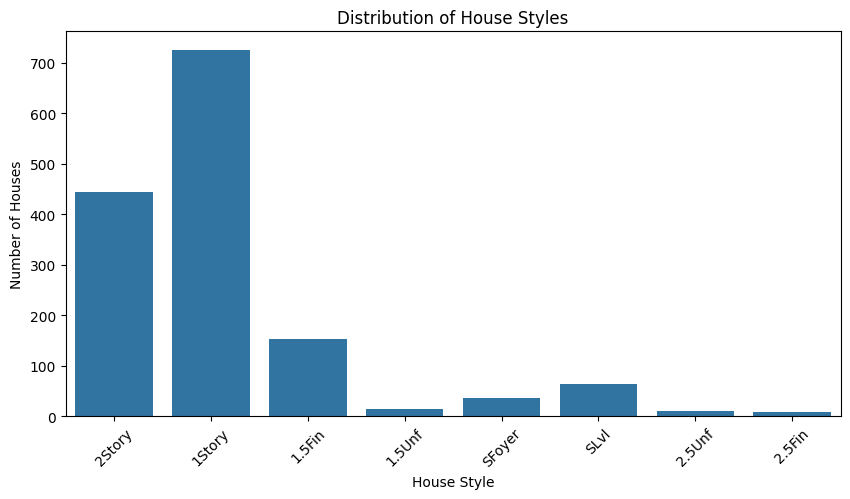

In [ ]:
plt.figure(figsize=(10, 5))

sns.countplot(data=df, x='HouseStyle')

plt.title('Distribution of House Styles')
plt.xlabel('House Style')
plt.ylabel('Number of Houses')
plt.xticks(rotation=45)
plt.show()

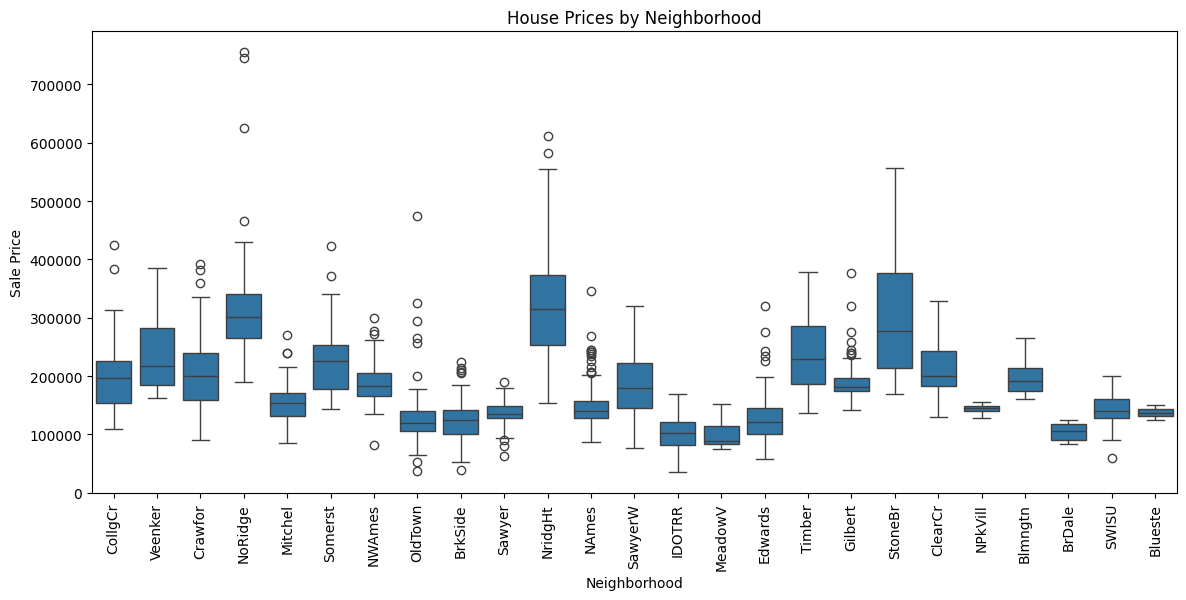

In [ ]:
plt.figure(figsize=(14, 6))

sns.boxplot(data=df, x='Neighborhood', y='SalePrice')

plt.title('House Prices by Neighborhood')
plt.xlabel('Neighborhood')
plt.ylabel('Sale Price')
plt.xticks(rotation=90)
plt.show()

In [ ]:
df.groupby('Neighborhood')['SalePrice'].mean().sort_values(ascending=False)

,SalePrice
Neighborhood,
NoRidge,335295.317073
NridgHt,316270.623377
StoneBr,310499.000000
Timber,242247.447368
Veenker,238772.727273
Somerst,225379.837209
ClearCr,212565.428571
Crawfor,210624.725490
CollgCr,197965.773333


In [ ]:
top10 = corr['SalePrice'].drop('SalePrice').abs().sort_values(ascending=False).head(10)

corr['SalePrice'].loc[top10.index]

,SalePrice
OverallQual,0.790982
GrLivArea,0.708624
GarageCars,0.640409
GarageArea,0.623431
TotalBsmtSF,0.613581
1stFlrSF,0.605852
FullBath,0.560664
TotRmsAbvGrd,0.533723
YearBuilt,0.522897
YearRemodAdd,0.507101


In [ ]:
cov_matrix = df.cov(numeric_only=True)

In [ ]:
top3 = top10.index[:3]

comparison = pd.DataFrame({
    'Correlation': corr.loc[top3, 'SalePrice'],
    'Covariance': cov_matrix.loc[top3, 'SalePrice']
})

comparison

,Correlation,Covariance
OverallQual,0.790982,8.690413e+04
GrLivArea,0.708624,2.958187e+07
GarageCars,0.640409,3.802018e+04


In [ ]:
corr.loc['GarageArea', 'GarageCars']

np.float64(0.882475414281462)

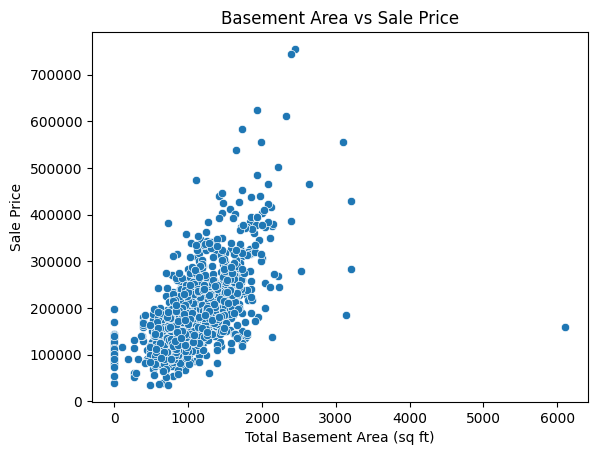

In [ ]:
sns.scatterplot(data=df, x='TotalBsmtSF', y='SalePrice')

plt.title('Basement Area vs Sale Price')
plt.xlabel('Total Basement Area (sq ft)')
plt.ylabel('Sale Price')
plt.show()

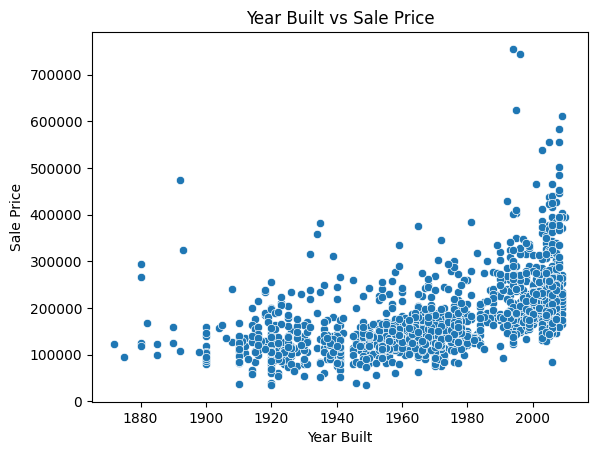

In [ ]:
sns.scatterplot(data=df, x='YearBuilt', y='SalePrice')

plt.title('Year Built vs Sale Price')
plt.xlabel('Year Built')
plt.ylabel('Sale Price')
plt.show()

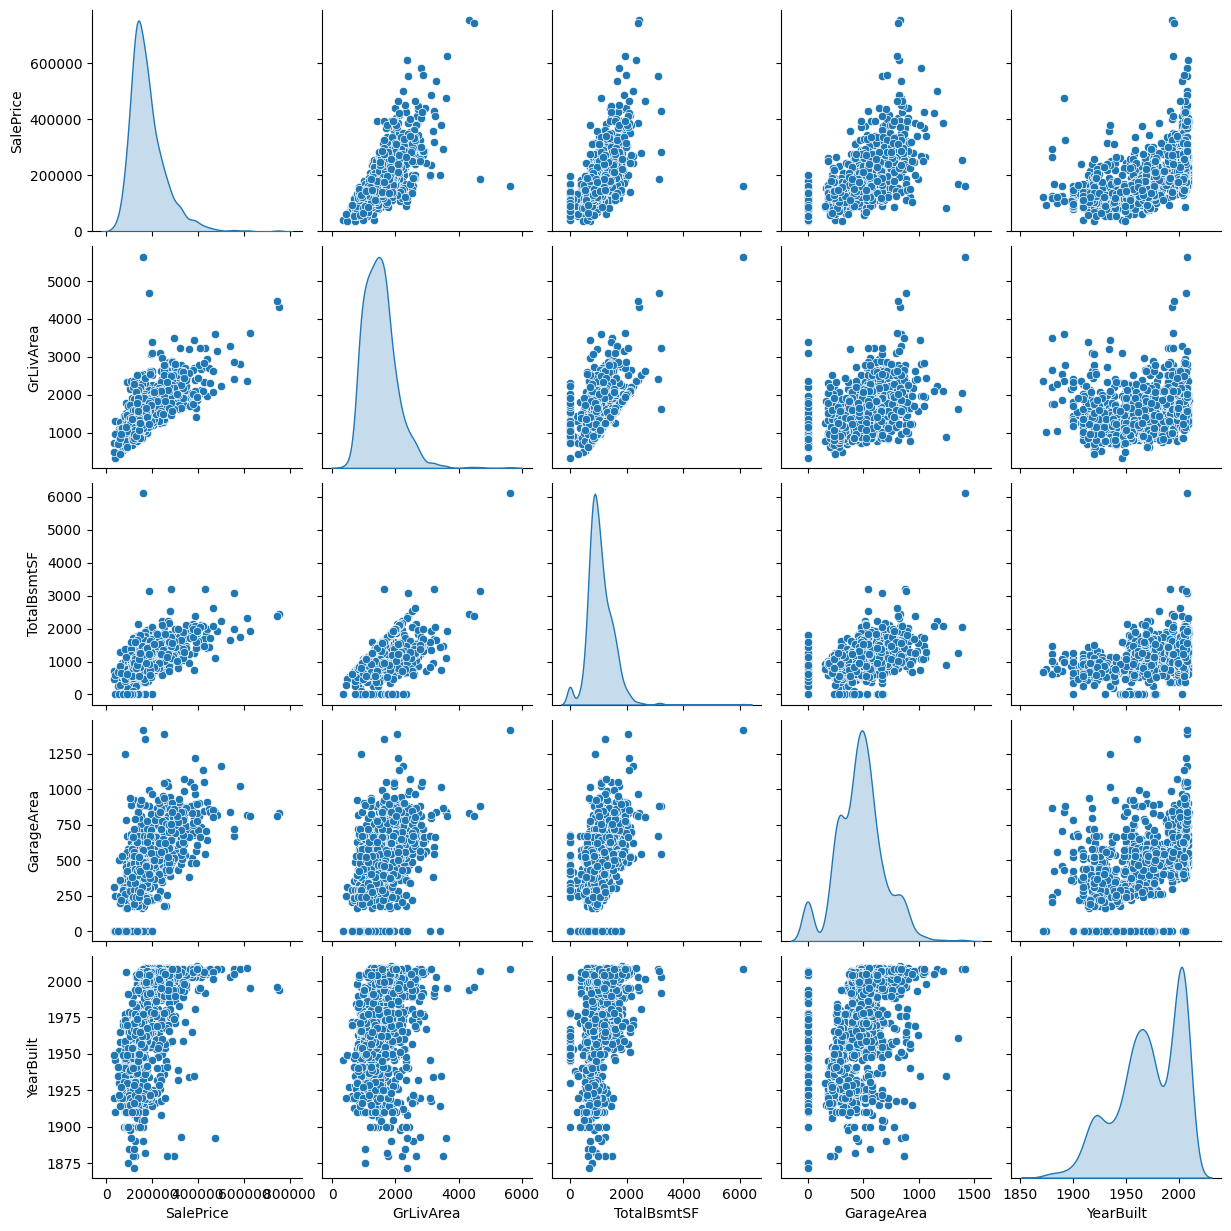

In [ ]:
sns.pairplot(
    df[['SalePrice', 'GrLivArea', 'TotalBsmtSF', 'GarageArea', 'YearBuilt']],
    diag_kind='kde'
)

plt.show()

In [ ]:
import numpy as np

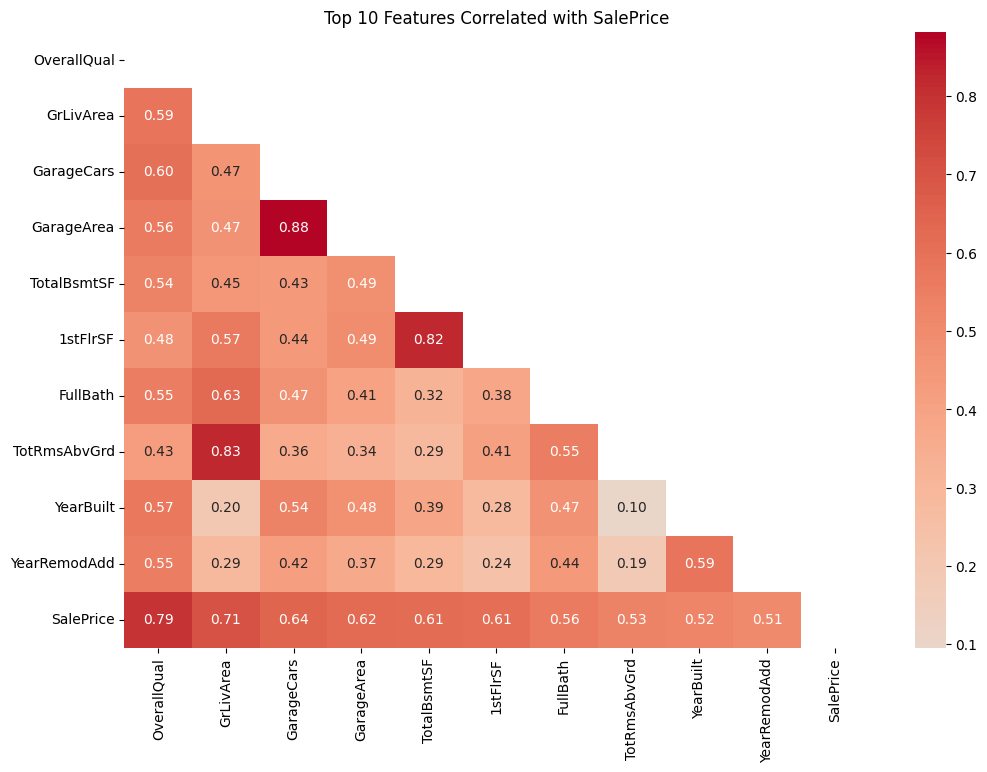

In [ ]:
top10_features = corr['SalePrice'].drop('SalePrice').abs().sort_values(ascending=False).head(10).index.tolist()

top10_features.append('SalePrice')

corr_top10 = df[top10_features].corr()

mask = np.triu(np.ones_like(corr_top10, dtype=bool))

plt.figure(figsize=(12, 8))

sns.heatmap(
    corr_top10,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0,
    mask=mask
)

plt.title('Top 10 Features Correlated with SalePrice')
plt.show()

In [ ]:
def detect_outliers_iqr(data, column):
    Q1 = data[column].quantile(0.25)
    Q3 = data[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = data[
        (data[column] < lower_bound) |
        (data[column] > upper_bound)
    ]

    return outliers

In [ ]:
from scipy.stats import zscore

def detect_outliers_zscore(data, column, threshold=3):
    z_scores = zscore(data[column].dropna())

    outliers = data.loc[data[column].dropna().index[
        abs(z_scores) > threshold
    ]]

    return outliers

In [ ]:
iqr_outliers = detect_outliers_iqr(df, 'GrLivArea')
zscore_outliers = detect_outliers_zscore(df, 'GrLivArea')

print("IQR Outliers:", len(iqr_outliers))
print("Z-score Outliers:", len(zscore_outliers))

IQR Outliers: 31
Z-score Outliers: 16


In [ ]:
iqr_outliers_price = detect_outliers_iqr(df, 'SalePrice')
zscore_outliers_price = detect_outliers_zscore(df, 'SalePrice')

print("IQR Outliers:", len(iqr_outliers_price))
print("Z-score Outliers:", len(zscore_outliers_price))

IQR Outliers: 61
Z-score Outliers: 22


In [ ]:
common_outliers = set(iqr_outliers_price.index).intersection(
    set(zscore_outliers_price.index)
)

print("Common SalePrice Outliers:", len(common_outliers))

Common SalePrice Outliers: 22


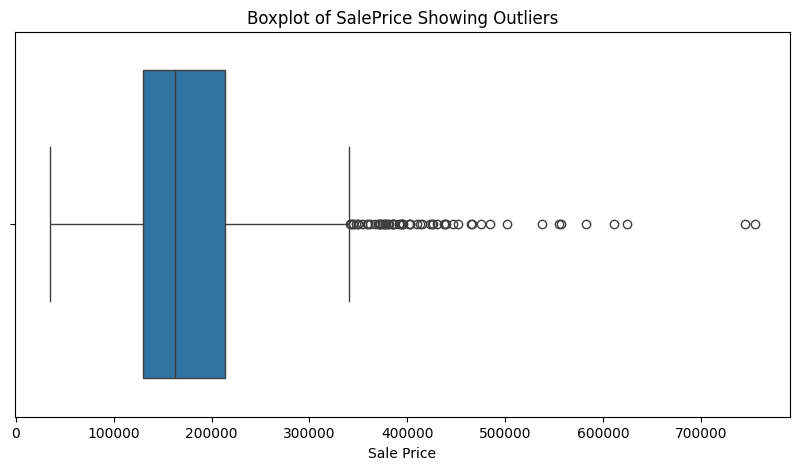

In [ ]:
plt.figure(figsize=(10, 5))

sns.boxplot(x=df['SalePrice'])

plt.title('Boxplot of SalePrice Showing Outliers')
plt.xlabel('Sale Price')

plt.show()

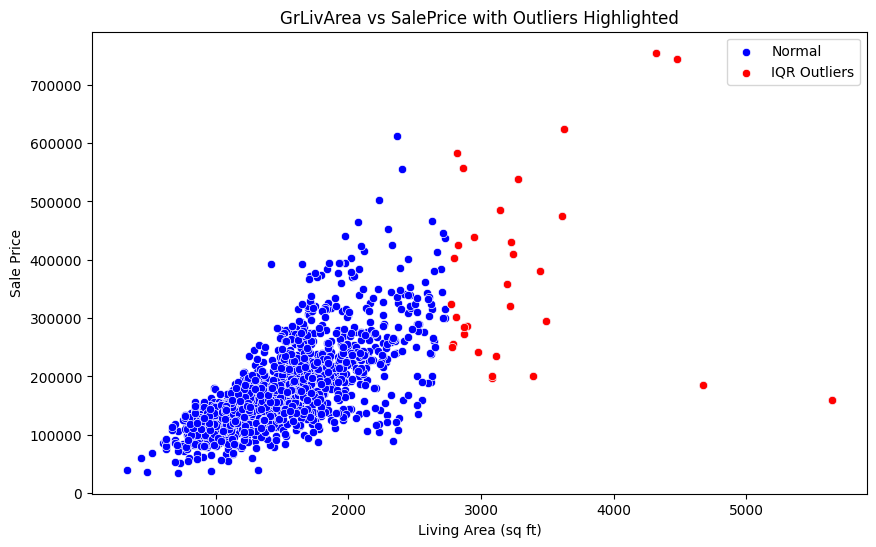

In [ ]:
plt.figure(figsize=(10, 6))

sns.scatterplot(data=df, x='GrLivArea', y='SalePrice', color='blue', label='Normal')

sns.scatterplot(
    data=df.loc[iqr_outliers.index],
    x='GrLivArea',
    y='SalePrice',
    color='red',
    label='IQR Outliers'
)

plt.title('GrLivArea vs SalePrice with Outliers Highlighted')
plt.xlabel('Living Area (sq ft)')
plt.ylabel('Sale Price')
plt.legend()
plt.show()

In [ ]:
df.sort_values(by='GrLivArea', ascending=False)[
    ['GrLivArea', 'SalePrice', 'OverallQual', 'Neighborhood']
].head(10)

,GrLivArea,SalePrice,OverallQual,Neighborhood
1298,5642,160000,10,Edwards
523,4676,184750,10,Edwards
1182,4476,745000,10,NoRidge
691,4316,755000,10,NoRidge
1169,3627,625000,10,NoRidge
185,3608,475000,10,OldTown
304,3493,295000,7,OldTown
1268,3447,381000,8,Crawfor
635,3395,200000,6,SWISU
769,3279,538000,8,StoneBr


In [ ]:
df_clean = df.copy()

print("Original Dataset Shape:", df.shape)
print("Cleaned Dataset Shape:", df_clean.shape)

Original Dataset Shape: (1460, 81)
Cleaned Dataset Shape: (1460, 81)


In [ ]:
print("Duplicate Rows:", df_clean.duplicated().sum())

Duplicate Rows: 0


In [ ]:
categorical_cols = df_clean.select_dtypes(include='object').columns

for col in categorical_cols:
    print(f"\n{col}:")
    print(df_clean[col].unique())


MSZoning:
['RL' 'RM' 'C (all)' 'FV' 'RH']

Street:
['Pave' 'Grvl']

Alley:
[nan 'Grvl' 'Pave']

LotShape:
['Reg' 'IR1' 'IR2' 'IR3']

LandContour:
['Lvl' 'Bnk' 'Low' 'HLS']

Utilities:
['AllPub' 'NoSeWa']

LotConfig:
['Inside' 'FR2' 'Corner' 'CulDSac' 'FR3']

LandSlope:
['Gtl' 'Mod' 'Sev']

Neighborhood:
['CollgCr' 'Veenker' 'Crawfor' 'NoRidge' 'Mitchel' 'Somerst' 'NWAmes'
 'OldTown' 'BrkSide' 'Sawyer' 'NridgHt' 'NAmes' 'SawyerW' 'IDOTRR'
 'MeadowV' 'Edwards' 'Timber' 'Gilbert' 'StoneBr' 'ClearCr' 'NPkVill'
 'Blmngtn' 'BrDale' 'SWISU' 'Blueste']

Condition1:
['Norm' 'Feedr' 'PosN' 'Artery' 'RRAe' 'RRNn' 'RRAn' 'PosA' 'RRNe']

Condition2:
['Norm' 'Artery' 'RRNn' 'Feedr' 'PosN' 'PosA' 'RRAn' 'RRAe']

BldgType:
['1Fam' '2fmCon' 'Duplex' 'TwnhsE' 'Twnhs']

HouseStyle:
['2Story' '1Story' '1.5Fin' '1.5Unf' 'SFoyer' 'SLvl' '2.5Unf' '2.5Fin']

RoofStyle:
['Gable' 'Hip' 'Gambrel' 'Mansard' 'Flat' 'Shed']

RoofMatl:
['CompShg' 'WdShngl' 'Metal' 'WdShake' 'Membran' 'Tar&Grv' 'Roll'
 'ClyTile']

E

In [ ]:
none_cols = ['PoolQC', 'Alley', 'Fence', 'FireplaceQu', 'GarageType']

df_clean[none_cols] = df_clean[none_cols].fillna('None')

print(df_clean[none_cols].isnull().sum())

PoolQC         0
Alley          0
Fence          0
FireplaceQu    0
GarageType     0
dtype: int64


In [ ]:
df_clean['LotFrontage'] = df_clean.groupby('Neighborhood')['LotFrontage'].transform(
    lambda x: x.fillna(x.median())
)

print("Missing LotFrontage:", df_clean['LotFrontage'].isnull().sum())

Missing LotFrontage: 0


In [ ]:
remaining_missing = df_clean.isnull().sum()

remaining_missing = remaining_missing[remaining_missing > 0].sort_values(ascending=False)

print(remaining_missing)

MiscFeature     1406
MasVnrType       872
GarageQual        81
GarageYrBlt       81
GarageFinish      81
GarageCond        81
BsmtFinType2      38
BsmtExposure      38
BsmtQual          37
BsmtFinType1      37
BsmtCond          37
MasVnrArea         8
Electrical         1
dtype: int64


In [ ]:
categorical_missing_cols = [
    'MiscFeature', 'MasVnrType',
    'GarageQual', 'GarageFinish', 'GarageCond',
    'BsmtFinType2', 'BsmtExposure',
    'BsmtQual', 'BsmtFinType1', 'BsmtCond'
]

df_clean[categorical_missing_cols] = df_clean[categorical_missing_cols].fillna('None')

print(df_clean[categorical_missing_cols].isnull().sum())

MiscFeature     0
MasVnrType      0
GarageQual      0
GarageFinish    0
GarageCond      0
BsmtFinType2    0
BsmtExposure    0
BsmtQual        0
BsmtFinType1    0
BsmtCond        0
dtype: int64


In [ ]:
df_clean['GarageYrBlt'] = df_clean['GarageYrBlt'].fillna(0)

df_clean['MasVnrArea'] = df_clean['MasVnrArea'].fillna(0)

print("GarageYrBlt missing:", df_clean['GarageYrBlt'].isnull().sum())
print("MasVnrArea missing:", df_clean['MasVnrArea'].isnull().sum())

GarageYrBlt missing: 0
MasVnrArea missing: 0


In [ ]:
df_clean['Electrical'] = df_clean['Electrical'].fillna(
    df_clean['Electrical'].mode()[0]
)

print("Missing Electrical values:", df_clean['Electrical'].isnull().sum())

Missing Electrical values: 0


In [ ]:
print("Total Missing Values:", df_clean.isnull().sum().sum())

Total Missing Values: 0


In [ ]:
invalid_years = df_clean[df_clean['YearBuilt'] > df_clean['YrSold']]

print("Invalid Year Records:", len(invalid_years))

Invalid Year Records: 0


In [ ]:
area_cols = ['LotArea', 'GrLivArea', 'TotalBsmtSF', 'GarageArea', 'MasVnrArea']

for col in area_cols:
    print(f"{col}: {(df_clean[col] < 0).sum()} negative values")

LotArea: 0 negative values
GrLivArea: 0 negative values
TotalBsmtSF: 0 negative values
GarageArea: 0 negative values
MasVnrArea: 0 negative values


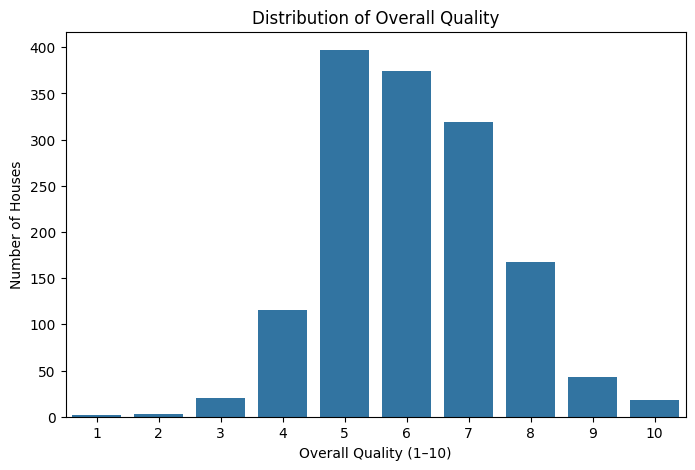

In [ ]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df_clean, x='OverallQual')

plt.title('Distribution of Overall Quality')
plt.xlabel('Overall Quality (1–10)')
plt.ylabel('Number of Houses')

plt.show()

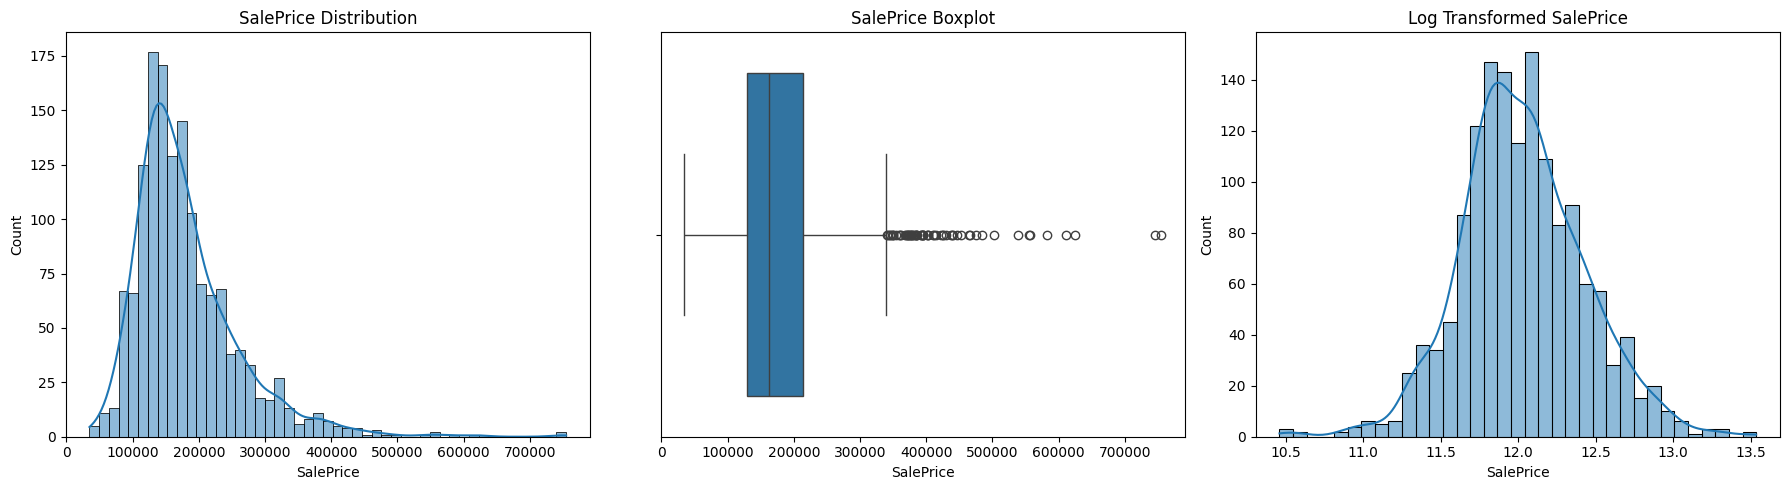

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.histplot(df_clean['SalePrice'], kde=True, ax=axes[0])
axes[0].set_title('SalePrice Distribution')

sns.boxplot(x=df_clean['SalePrice'], ax=axes[1])
axes[1].set_title('SalePrice Boxplot')

sns.histplot(np.log1p(df_clean['SalePrice']), kde=True, ax=axes[2])
axes[2].set_title('Log Transformed SalePrice')

plt.tight_layout()
plt.show()

In [ ]:
print("Original SalePrice Skewness:", df_clean['SalePrice'].skew())

print("Log Transformed Skewness:", np.log1p(df_clean['SalePrice']).skew())

Original SalePrice Skewness: 1.8828757597682129
Log Transformed Skewness: 0.12134661989685333


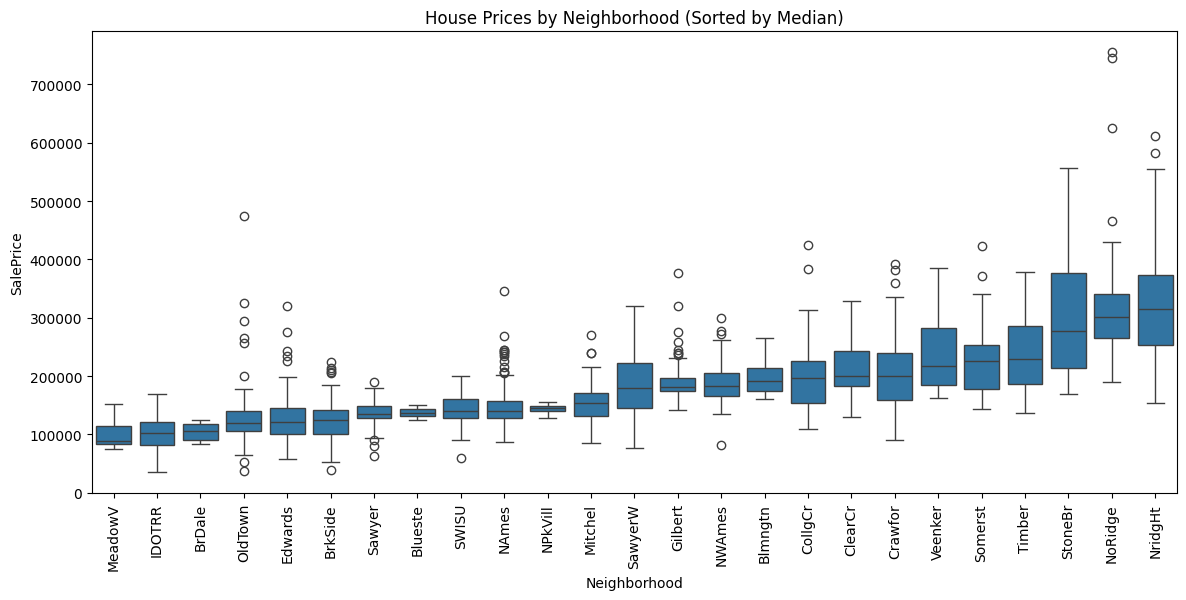

In [ ]:
neighborhood_order = df_clean.groupby('Neighborhood')['SalePrice'].median().sort_values().index

plt.figure(figsize=(14, 6))

sns.boxplot(
    data=df_clean,
    x='Neighborhood',
    y='SalePrice',
    order=neighborhood_order
)

plt.title('House Prices by Neighborhood (Sorted by Median)')
plt.xticks(rotation=90)
plt.show()

In [ ]:
print("Mean SalePrice:", df_clean['SalePrice'].mean())

print("Median SalePrice:", df_clean['SalePrice'].median())

Mean SalePrice: 180921.19589041095
Median SalePrice: 163000.0


In [ ]:
print("Neighborhood Mode:", df_clean['Neighborhood'].mode()[0])

print("\nNeighborhood Counts:")
print(df_clean['Neighborhood'].value_counts())

Neighborhood Mode: NAmes

Neighborhood Counts:
Neighborhood
NAmes      225
CollgCr    150
OldTown    113
Edwards    100
Somerst     86
Gilbert     79
NridgHt     77
Sawyer      74
NWAmes      73
SawyerW     59
BrkSide     58
Crawfor     51
Mitchel     49
NoRidge     41
Timber      38
IDOTRR      37
ClearCr     28
SWISU       25
StoneBr     25
Blmngtn     17
MeadowV     17
BrDale      16
Veenker     11
NPkVill      9
Blueste      2
Name: count, dtype: int64


In [ ]:
print("HouseStyle Mode:", df_clean['HouseStyle'].mode()[0])

print("\nHouseStyle Counts:")
print(df_clean['HouseStyle'].value_counts())

HouseStyle Mode: 1Story

HouseStyle Counts:
HouseStyle
1Story    726
2Story    445
1.5Fin    154
SLvl       65
SFoyer     37
1.5Unf     14
2.5Unf     11
2.5Fin      8
Name: count, dtype: int64


In [ ]:
numerical_cols = df_clean.select_dtypes(include=['int64', 'float64']).columns.tolist()

categorical_cols = df_clean.select_dtypes(include=['object']).columns.tolist()

ordinal_cols = [
    'OverallQual', 'OverallCond', 'ExterQual',
    'ExterCond', 'KitchenQual', 'HeatingQC',
    'BsmtQual', 'BsmtCond', 'FireplaceQu',
    'GarageQual', 'GarageCond'
]

print("Numerical Columns:", len(numerical_cols))
print("Categorical Columns:", len(categorical_cols))
print("Ordinal Columns:", ordinal_cols)

Numerical Columns: 38
Categorical Columns: 43
Ordinal Columns: ['OverallQual', 'OverallCond', 'ExterQual', 'ExterCond', 'KitchenQual', 'HeatingQC', 'BsmtQual', 'BsmtCond', 'FireplaceQu', 'GarageQual', 'GarageCond']


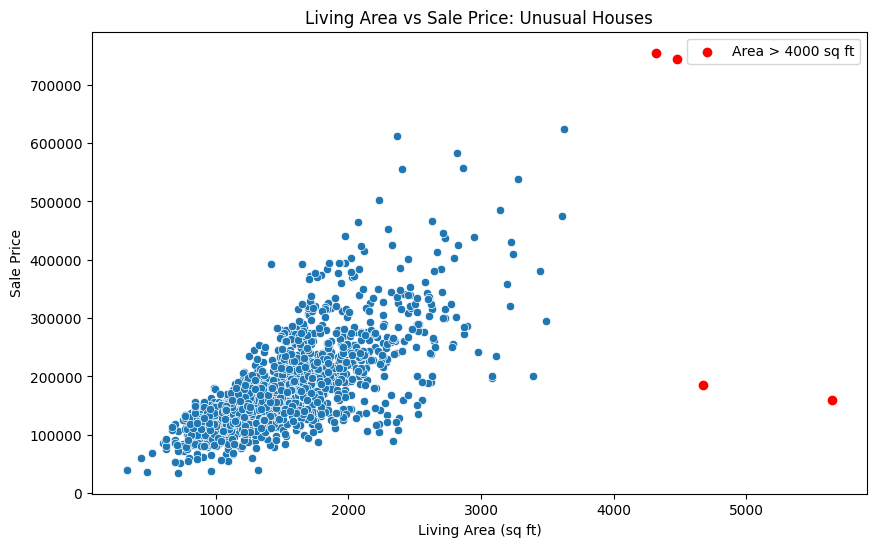

In [ ]:
plt.figure(figsize=(10, 6))

sns.scatterplot(data=df_clean, x='GrLivArea', y='SalePrice')

unusual = df_clean[df_clean['GrLivArea'] > 4000]

plt.scatter(
    unusual['GrLivArea'],
    unusual['SalePrice'],
    color='red',
    label='Area > 4000 sq ft'
)

plt.title('Living Area vs Sale Price: Unusual Houses')
plt.xlabel('Living Area (sq ft)')
plt.ylabel('Sale Price')
plt.legend()
plt.show()

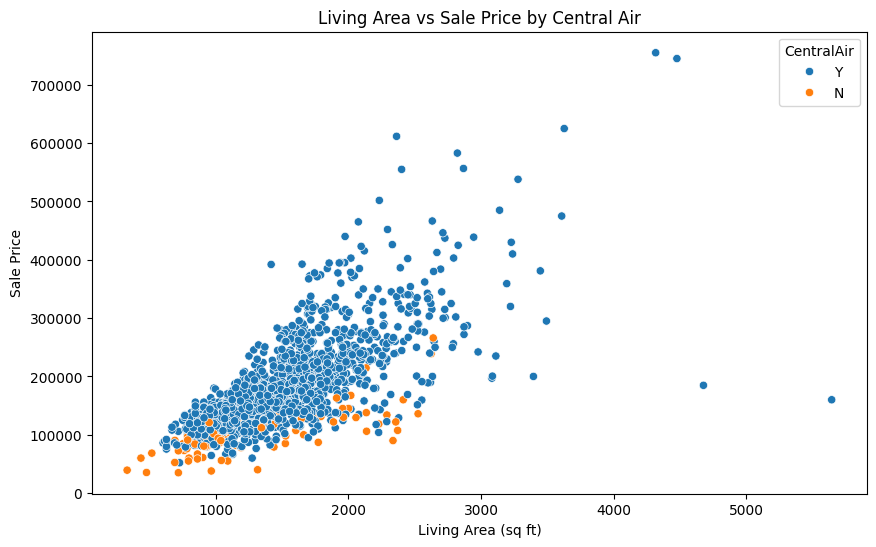

In [ ]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df_clean,
    x='GrLivArea',
    y='SalePrice',
    hue='CentralAir'
)

plt.title('Living Area vs Sale Price by Central Air')
plt.xlabel('Living Area (sq ft)')
plt.ylabel('Sale Price')

plt.show()

In [ ]:
neighborhood_avg = df_clean.groupby('Neighborhood')['SalePrice'].mean()

top10_neighborhoods = neighborhood_avg.sort_values(ascending=False).head(10)

axes[0, 1].barh(
    top10_neighborhoods.index,
    top10_neighborhoods.values
)

axes[0, 1].set_title('Top 10 Neighborhoods by Average Price')
axes[0, 1].set_xlabel('Average Sale Price')

axes[0, 1].invert_yaxis()

plt.tight_layout()
plt.show()

<Figure size 640x480 with 0 Axes>

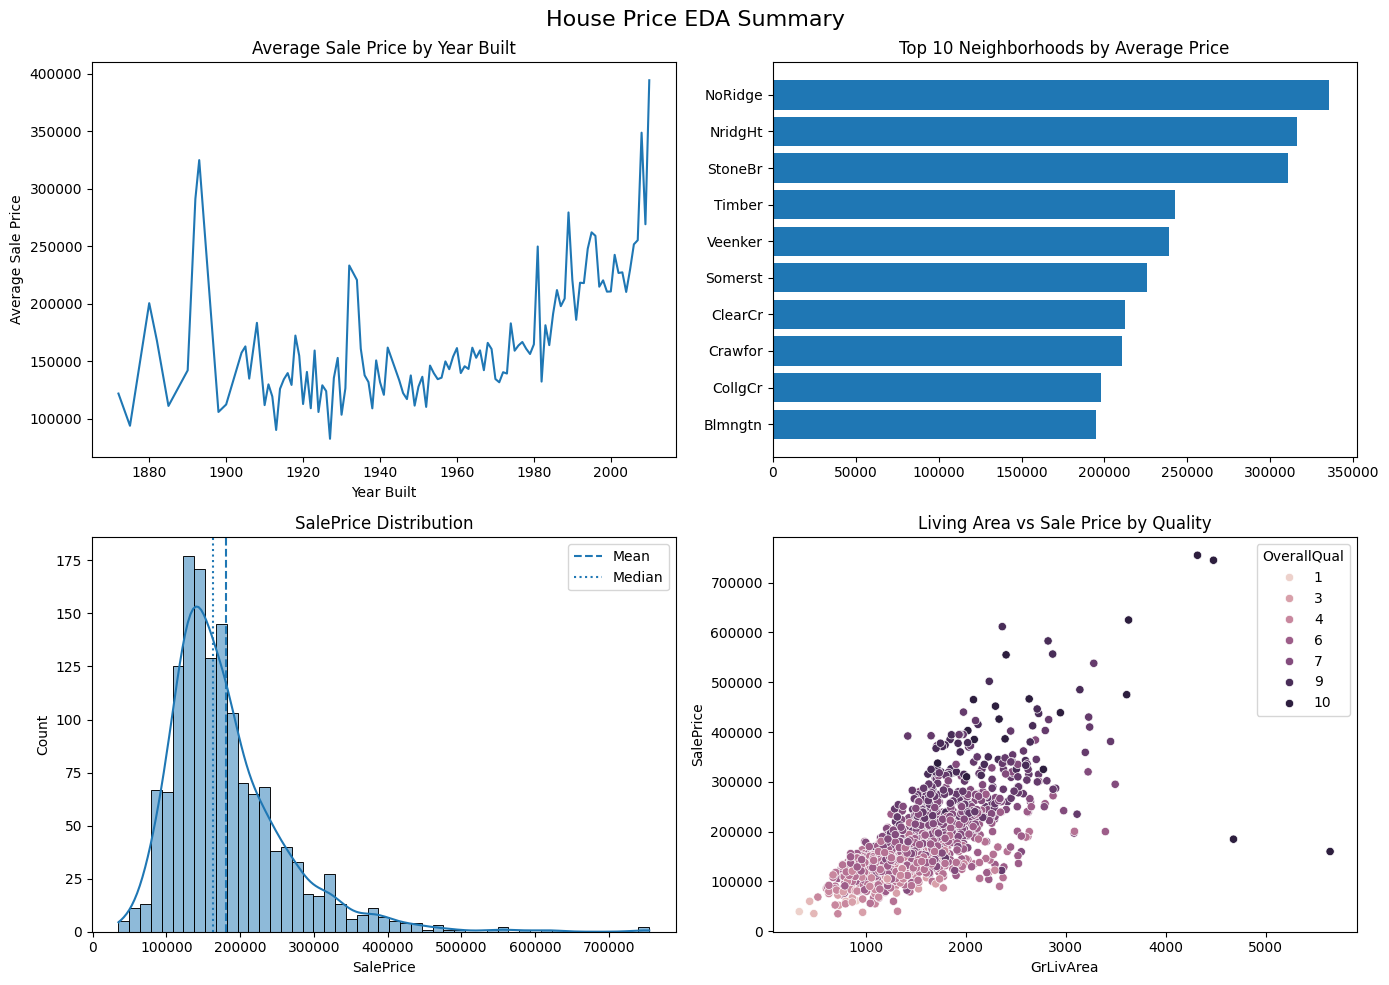

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Panel 1
yearly_price = df_clean.groupby('YearBuilt')['SalePrice'].mean()
axes[0, 0].plot(yearly_price.index, yearly_price.values)
axes[0, 0].set_title('Average Sale Price by Year Built')
axes[0, 0].set_xlabel('Year Built')
axes[0, 0].set_ylabel('Average Sale Price')

# Panel 2
top10 = df_clean.groupby('Neighborhood')['SalePrice'].mean().nlargest(10)
axes[0, 1].barh(top10.index, top10.values)
axes[0, 1].set_title('Top 10 Neighborhoods by Average Price')
axes[0, 1].invert_yaxis()

# Panel 3
sns.histplot(df_clean['SalePrice'], kde=True, ax=axes[1, 0])
axes[1, 0].axvline(df_clean['SalePrice'].mean(), linestyle='--', label='Mean')
axes[1, 0].axvline(df_clean['SalePrice'].median(), linestyle=':', label='Median')
axes[1, 0].set_title('SalePrice Distribution')
axes[1, 0].legend()

# Panel 4
sns.scatterplot(data=df_clean, x='GrLivArea', y='SalePrice',
                hue='OverallQual', ax=axes[1, 1])
axes[1, 1].set_title('Living Area vs Sale Price by Quality')

fig.suptitle('House Price EDA Summary', fontsize=16)
plt.tight_layout()
plt.savefig('eda_dashboard.png', dpi=300, bbox_inches='tight')
plt.show()

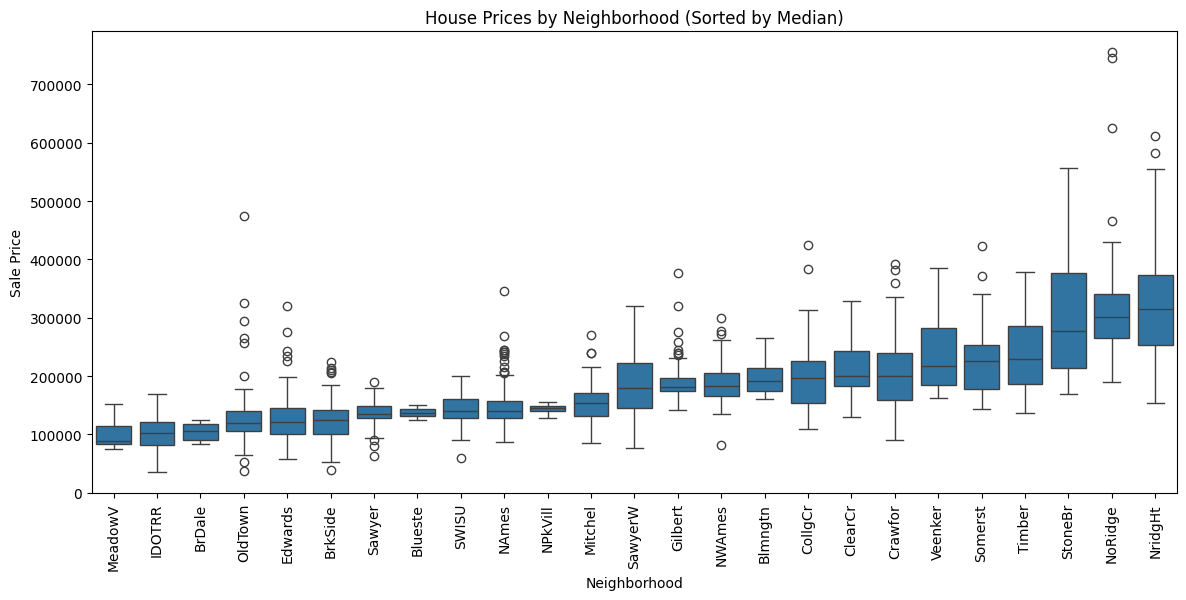

In [ ]:
neighborhood_order = df_clean.groupby('Neighborhood')['SalePrice'].median().sort_values().index

plt.figure(figsize=(14, 6))

sns.boxplot(
    data=df_clean,
    x='Neighborhood',
    y='SalePrice',
    order=neighborhood_order
)

plt.title('House Prices by Neighborhood (Sorted by Median)')
plt.xlabel('Neighborhood')
plt.ylabel('Sale Price')
plt.xticks(rotation=90)
plt.show()

In [ ]:
common_area_outliers = set(iqr_outliers.index).intersection(
    set(zscore_outliers.index)
)

print("Common GrLivArea Outliers:", len(common_area_outliers))


Common GrLivArea Outliers: 16


In [ ]:
for col in categorical_cols:
    if df_clean[col].dtype == 'object':
        spaces = df_clean[col].astype(str).str.strip() != df_clean[col].astype(str)
        if spaces.any():
            print(col, ":", spaces.sum(), "values with extra spaces")

# 1. Introduction

## Project: Exploratory Data Analysis of House Prices

### Objective
The objective of this project is to perform Exploratory Data Analysis (EDA) on the Ames Housing Dataset to understand the factors affecting house prices.

### Dataset Description
The dataset contains 1,460 house records and 81 columns, including numerical, categorical and ordinal features. The target variable is `SalePrice`.

### Tools and Libraries
- Python
- Pandas and NumPy
- Matplotlib and Seaborn
- SciPy

### Key Questions
1. What is the distribution of house prices?
2. Which numerical features have the strongest correlation with SalePrice?
3. How does Overall Quality affect house prices?
4. Which neighborhoods have higher house prices?
5. Are there unusual observations or outliers?
6. How should missing values be handled?

# 2. Conclusion

The Exploratory Data Analysis of the Ames Housing Dataset helped identify important patterns and relationships in house prices.

### Key Findings

1. The dataset contains 1,460 records and 81 columns.
2. SalePrice is positively skewed, with a skewness of approximately 1.88. Applying a log transformation reduced the skewness to approximately 0.12.
3. OverallQual (0.79) and GrLivArea (0.71) showed strong positive correlations with SalePrice.
4. GarageArea and GarageCars had a strong positive correlation of approximately 0.88.
5. House prices vary across neighborhoods, indicating that location is an important factor to explore.
6. The IQR and Z-score methods identified unusual observations in SalePrice and GrLivArea. These records were retained because they were not confirmed to be data errors.
7. Data cleaning removed all missing values from the cleaned dataset. No duplicate rows or negative area values were found.

### Final Observation

Overall, the analysis shows that house quality, living area, garage capacity and neighborhood are useful factors for understanding house prices. However, correlation does not imply causation. This project is limited to Exploratory Data Analysis and does not build a machine-learning prediction model.

In [ ]:
import os

print("Dashboard saved:", os.path.exists("eda_dashboard.png"))

Dashboard saved: True


In [ ]:
from google.colab import files

files.download('eda_dashboard.png')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
columns = ['SalePrice', 'GrLivArea', 'LotArea']

for col in columns:
    print(f"\n--- {col} ---")
    print("Mean:", df_clean[col].mean())
    print("Median:", df_clean[col].median())
    print("Mode:", df_clean[col].mode()[0])
    print("Standard Deviation:", df_clean[col].std())
    print("Variance:", df_clean[col].var())
    print("Range:", df_clean[col].max() - df_clean[col].min())
    print("IQR:", df_clean[col].quantile(0.75) - df_clean[col].quantile(0.25))
    print("Skewness:", df_clean[col].skew())
    print("Kurtosis:", df_clean[col].kurt())


--- SalePrice ---
Mean: 180921.19589041095
Median: 163000.0
Mode: 140000
Standard Deviation: 79442.50288288663
Variance: 6311111264.297451
Range: 720100
IQR: 84025.0
Skewness: 1.8828757597682129
Kurtosis: 6.536281860064529

--- GrLivArea ---
Mean: 1515.463698630137
Median: 1464.0
Mode: 864
Standard Deviation: 525.4803834232027
Variance: 276129.63336259616
Range: 5308
IQR: 647.25
Skewness: 1.3665603560164552
Kurtosis: 4.895120580693174

--- LotArea ---
Mean: 10516.828082191782
Median: 9478.5
Mode: 7200
Standard Deviation: 9981.264932379147
Variance: 99625649.6503417
Range: 213945
IQR: 4048.0
Skewness: 12.207687851233496
Kurtosis: 203.24327101886033


### Interpretation of Descriptive Statistics

- SalePrice has a mean greater than its median, indicating a positively skewed distribution.
- GrLivArea also shows positive skewness, meaning a few houses have unusually large living areas.
- LotArea has very high skewness and kurtosis, indicating the presence of extreme lot sizes.
- The standard deviation and IQR help measure the spread of the data, while variance measures squared deviations from the mean.

These findings show why median, IQR and distribution plots are useful alongside the mean and standard deviation.

In [ ]:
ordinal_cols = [
    'OverallQual', 'OverallCond', 'ExterQual',
    'ExterCond', 'KitchenQual', 'HeatingQC',
    'BsmtQual', 'BsmtCond', 'FireplaceQu',
    'GarageQual', 'GarageCond'
]

summary = []

for col in df_clean.columns:
    if col in ordinal_cols:
        var_type = 'Ordinal'
    elif pd.api.types.is_numeric_dtype(df_clean[col]):
        var_type = 'Numerical'
    else:
        var_type = 'Categorical'

    summary.append({
        'Column Name': col,
        'Variable Type': var_type,
        'Unique Values': df_clean[col].nunique(),
        'Example Values': list(df_clean[col].dropna().unique()[:5])
    })

variable_summary = pd.DataFrame(summary)

display(variable_summary)

,Column Name,Variable Type,Unique Values,Example Values
0,Id,Numerical,1460,"[1, 2, 3, 4, 5]"
1,MSSubClass,Numerical,15,"[60, 20, 70, 50, 190]"
2,MSZoning,Categorical,5,"[RL, RM, C (all), FV, RH]"
3,LotFrontage,Numerical,115,"[65.0, 80.0, 68.0, 60.0, 84.0]"
4,LotArea,Numerical,1073,"[8450, 9600, 11250, 9550, 14260]"
...,...,...,...,...
76,MoSold,Numerical,12,"[2, 5, 9, 12, 10]"
77,YrSold,Numerical,5,"[2008, 2007, 2006, 2009, 2010]"
78,SaleType,Categorical,9,"[WD, New, COD, ConLD, ConLI]"
79,SaleCondition,Categorical,6,"[Normal, Abnorml, Partial, AdjLand, Alloca]"


In [ ]:
df_ordinal = df_clean.copy()

ordinal_map = {
    'ExterQual': ['Po', 'Fa', 'TA', 'Gd', 'Ex', 'None'],
    'KitchenQual': ['Po', 'Fa', 'TA', 'Gd', 'Ex', 'None']
}

for col, order in ordinal_map.items():
    df_ordinal[col] = pd.Categorical(
        df_ordinal[col],
        categories=order,
        ordered=True
    )

print("ExterQual ordered:", df_ordinal['ExterQual'].cat.ordered)
print("KitchenQual ordered:", df_ordinal['KitchenQual'].cat.ordered)

ExterQual ordered: True
KitchenQual ordered: True


### Interpretation of Variable Types

The dataset contains numerical, categorical and ordinal variables.

- Numerical variables represent measurable quantities, such as SalePrice, LotArea and GrLivArea.
- Categorical variables represent groups or labels, such as Neighborhood, HouseStyle and MSZoning.
- Ordinal variables have a meaningful order, such as OverallQual, ExterQual and KitchenQual.
- OverallQual is stored as a number but represents an ordered quality rating.

Identifying variable types helps us select suitable statistical methods and visualizations.

### Interpretation of Correlation and Covariance

OverallQual and GrLivArea are among the strongest features positively correlated with SalePrice.

GarageArea and GarageCars have a strong positive correlation of approximately 0.88. This relationship is reasonable because houses with greater garage capacity generally have larger garage areas.

Correlation is easier to compare than covariance because correlation is standardized between -1 and +1, whereas covariance depends on the units and scale of the variables.

**Important:** Correlation shows association, not causation.


### Interpretation of Outlier Detection

The IQR and Z-score methods identified different numbers of outliers.

- The IQR method identifies values outside 1.5 times the interquartile range from the quartiles.
- The Z-score method identifies values more than 3 standard deviations from the mean.
- Z-score detected fewer outliers because extreme values in right-skewed distributions can influence the mean and standard deviation.
- The common outliers were identified by both methods.

After inspecting unusual observations, we retained the records because they were not confirmed to be data-entry errors. They may represent genuine but unusual house sales.

### Initial Dataset Overview

- The dataset contains 1,460 rows and 81 columns.
- It includes information about house features, location, quality and sale prices.
- A total of 19 columns contain missing values.
- SalePrice is the target variable for our exploratory analysis.
- Several categorical columns contain missing values because certain house features may not be present.

The dataset provides sufficient information to explore the factors associated with house prices.

### Interpretation of Neighborhood and HouseStyle

- NAmes is the most frequently occurring Neighborhood, with 225 houses.
- 1Story is the most common HouseStyle, with 726 houses.
- The dataset contains more single-storey houses than other house styles.
- House prices vary across neighborhoods, indicating that location is an important factor in property prices.

These observations help us understand the distribution of houses across locations and building styles.


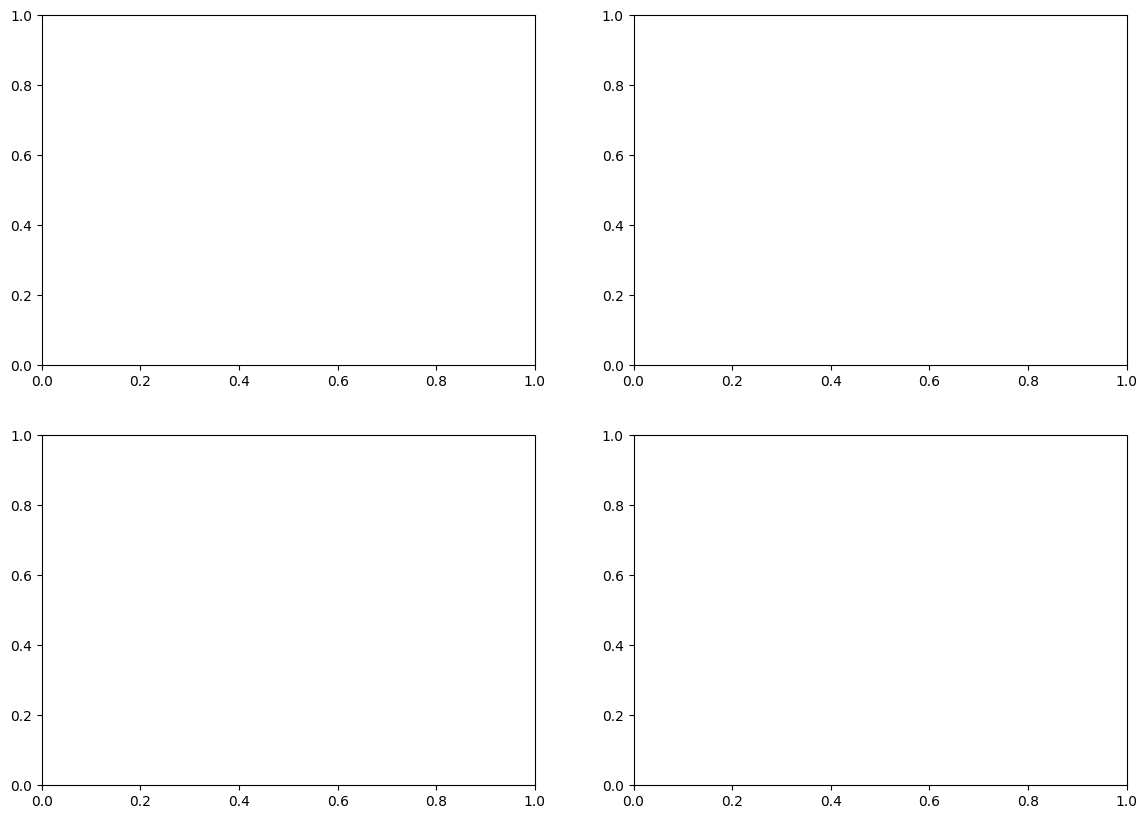

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

In [ ]:
import os

print(os.path.exists("eda_dashboard.png"))


True


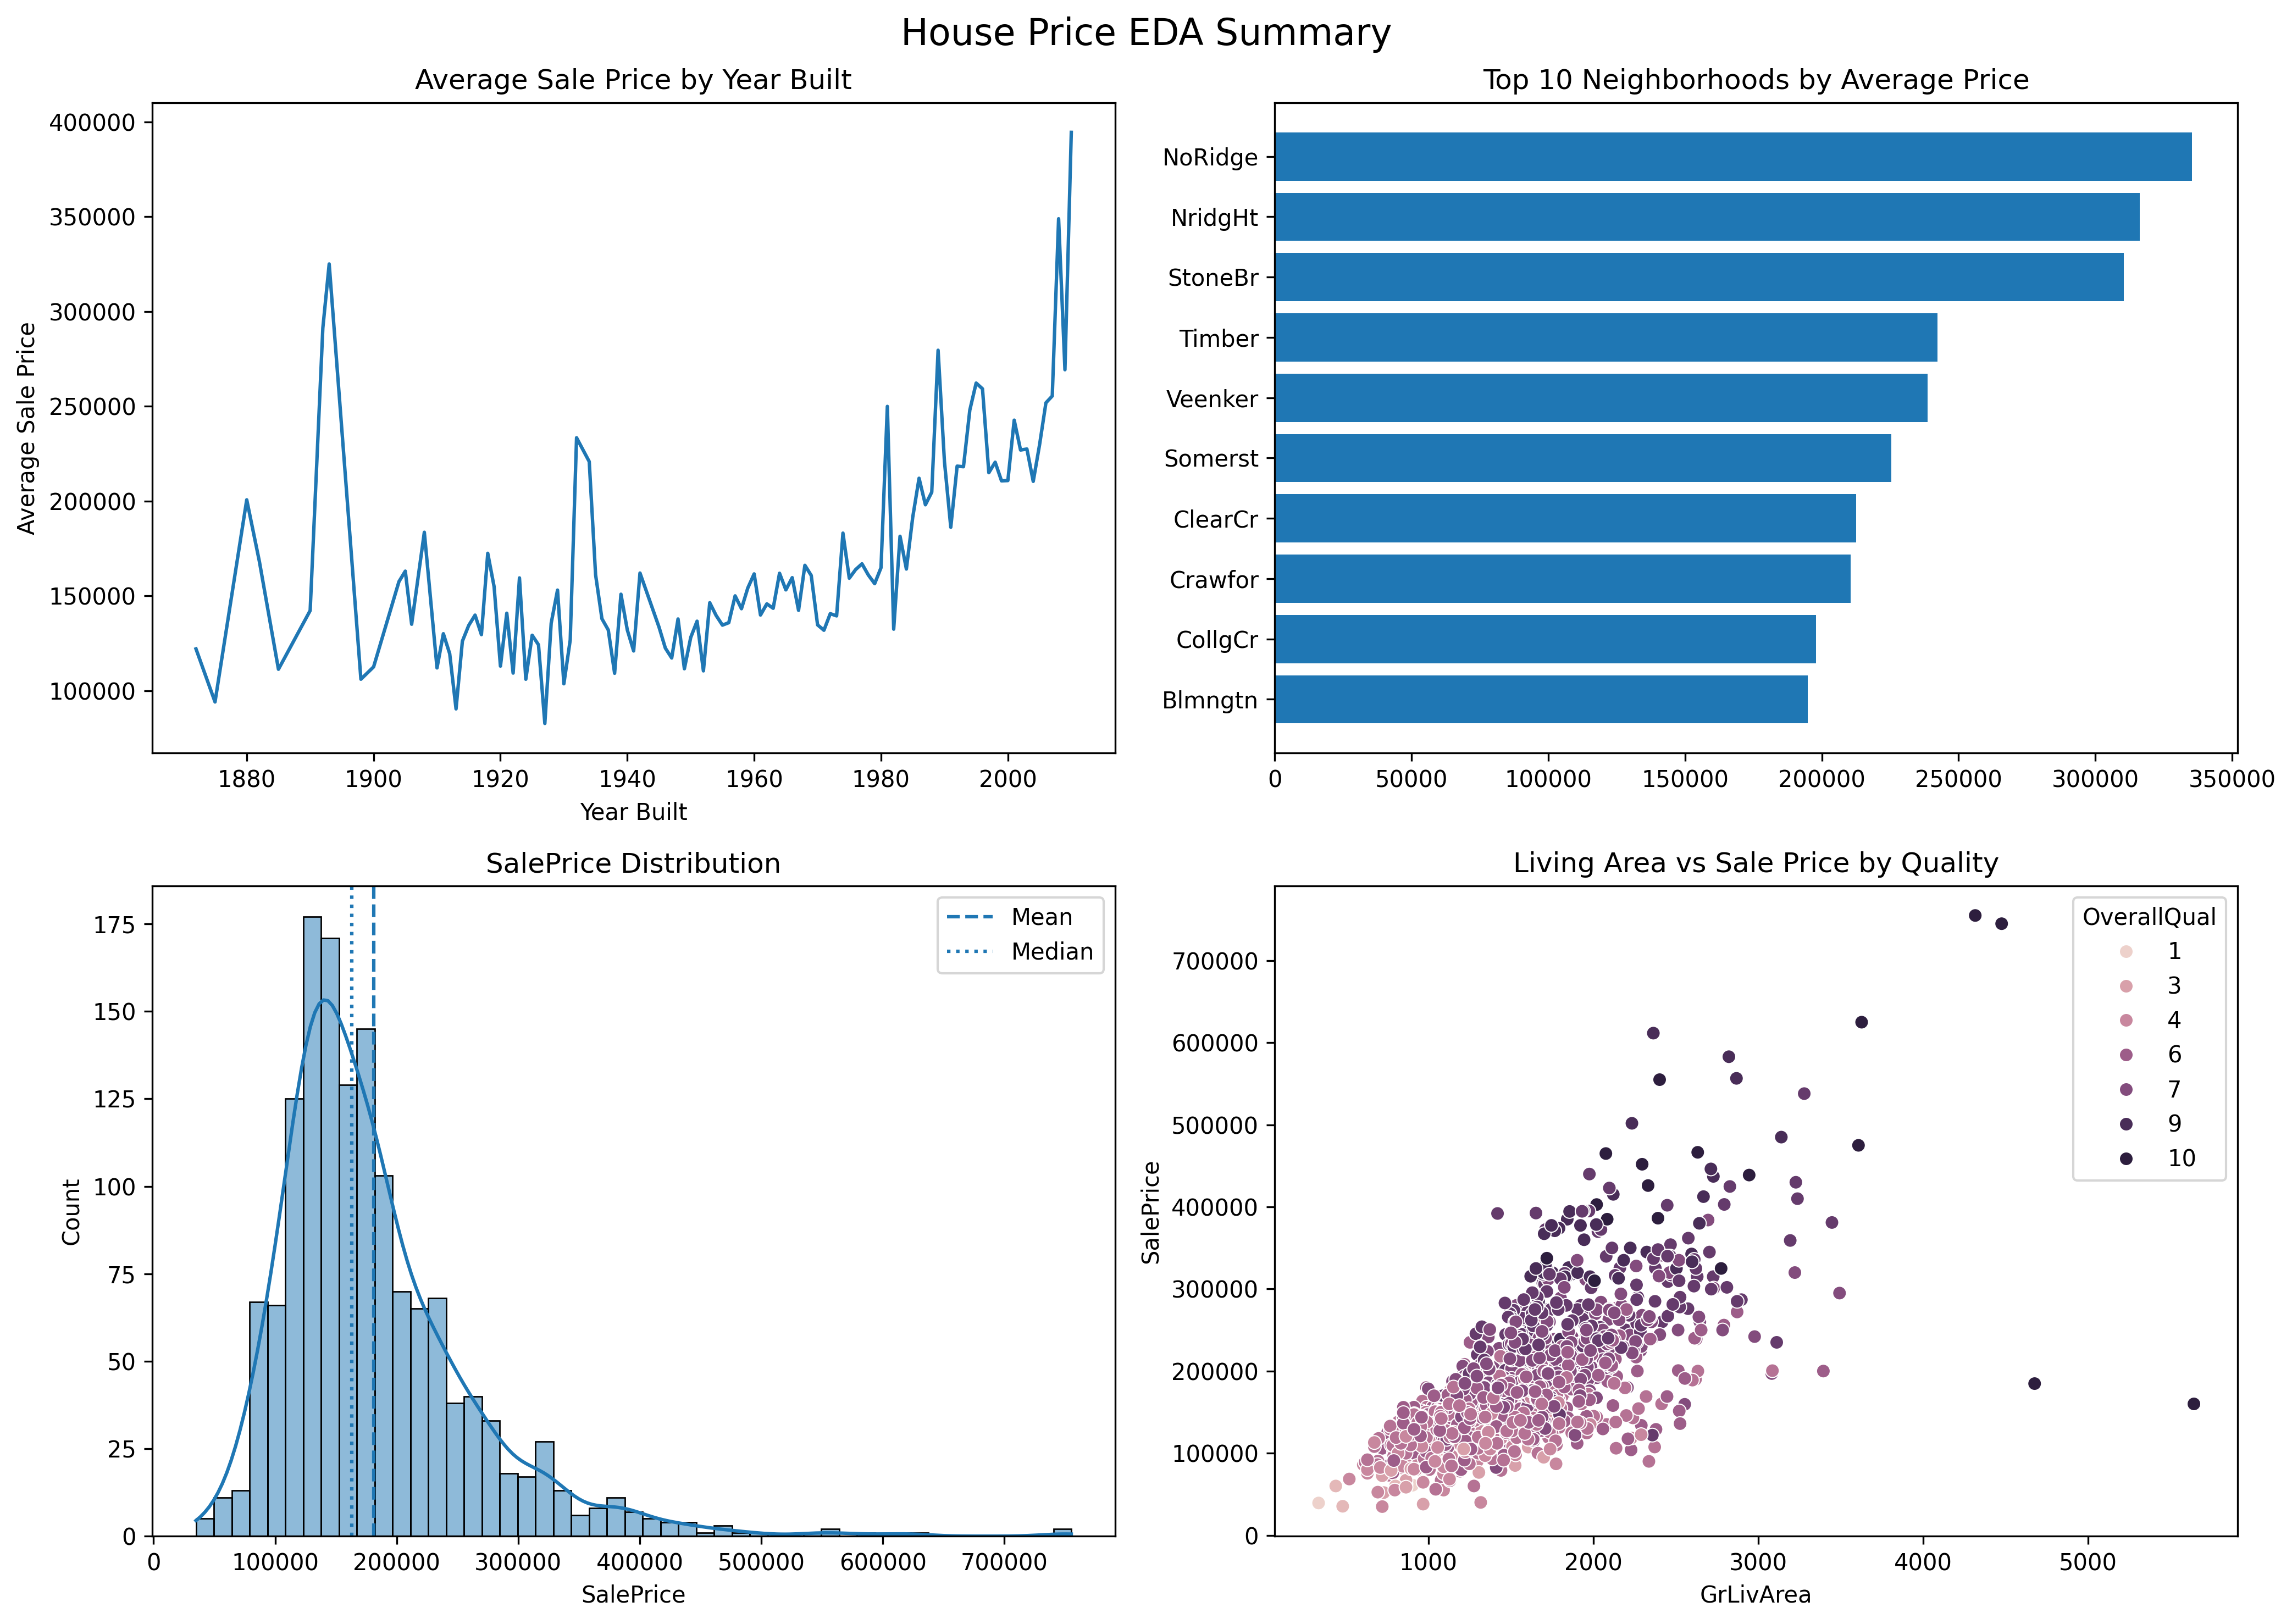

In [ ]:
from IPython.display import Image, display

display(Image(filename='eda_dashboard.png'))
